In [1]:
!wget -O 'Project_train.csv' 'https://hr-projects-assets-prod.s3.amazonaws.com/bkj9j39cpbb/fcf0ec1f3785668db3f2122ed605ebc0/Project_train.csv'

--2026-08-26 10:32:58--  https://hr-projects-assets-prod.s3.amazonaws.com/bkj9j39cpbb/fcf0ec1f3785668db3f2122ed605ebc0/Project_train.csv
Resolving hr-projects-assets-prod.s3.amazonaws.com (hr-projects-assets-prod.s3.amazonaws.com)... 16.15.223.17, 16.15.207.28, 52.217.225.129, ...
Connecting to hr-projects-assets-prod.s3.amazonaws.com (hr-projects-assets-prod.s3.amazonaws.com)|16.15.223.17|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 72687753 (69M) [binary/octet-stream]
Saving to: ‘Project_train.csv’

Project_train.csv   100%[===================>]  69.32M  15.2KB/s    in 48m 48s 

2026-08-26 11:21:48 (24.2 KB/s) - ‘Project_train.csv’ saved [72687753/72687753]



In [2]:
!wget -O 'Project_test.csv' 'https://hr-projects-assets-prod.s3.amazonaws.com/bkj9j39cpbb/359662815ce4d41539803bd3dbc34ee3/Project_test.csv'

--2026-08-26 11:21:48--  https://hr-projects-assets-prod.s3.amazonaws.com/bkj9j39cpbb/359662815ce4d41539803bd3dbc34ee3/Project_test.csv
Resolving hr-projects-assets-prod.s3.amazonaws.com (hr-projects-assets-prod.s3.amazonaws.com)... 16.15.252.211, 16.15.223.219, 16.182.40.185, ...
Connecting to hr-projects-assets-prod.s3.amazonaws.com (hr-projects-assets-prod.s3.amazonaws.com)|16.15.252.211|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 15910859 (15M) [binary/octet-stream]
Saving to: ‘Project_test.csv’

Project_test.csv    100%[===================>]  15.17M  16.0KB/s    in 14m 9s  

2026-08-26 11:35:58 (18.3 KB/s) - ‘Project_test.csv’ saved [15910859/15910859]



## Basic probing

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train = pd.read_csv('Project_train.csv')
test = pd.read_csv('Project_test.csv')
train = train.drop(columns=["Unnamed: 0"])
test = test.drop(columns=["Unnamed: 0"])
print(train.shape, test.shape)


(90000, 67) (19707, 67)


In [7]:
train.head(5)

,0,1,2,3,4,5,6,7,8,9,...,57,58,59,60,61,62,63,64,65,TARGET
0,5874.524387,1072.671848,41440.76212,41440.23732,70.405148,7.392780,70.377281,23229.69262,23229.72655,70.378864,...,23936.99077,21670.19233,71.518948,11.399004,78.006816,26437.161240,23811.09670,141.997532,22.474794,0.013314
1,6124.154099,1072.802927,41440.76212,41442.22458,70.456758,7.356050,70.379576,23229.76020,23230.10472,70.273618,...,22053.23653,14626.73339,48.124991,-99.618253,-115.120518,7705.543821,22665.35143,-377.287072,-73.700375,-0.000448
2,5905.732593,1072.802927,41443.14358,41442.30403,70.422472,7.417794,70.376448,23229.48142,23229.61008,70.474265,...,23430.24573,31251.55292,71.535567,53.482719,106.179152,37586.677270,23251.62576,261.098973,22.565621,0.000244
3,6029.325221,1072.802927,41440.76212,41442.25682,70.458533,7.366031,70.379221,23230.08433,23229.87971,70.288944,...,23193.67720,15867.01579,70.369496,-12.169114,63.930236,10052.351290,23229.64352,-10.549985,4.656636,-0.000628
4,6142.360146,1072.802927,41443.14358,41442.46480,70.413623,7.411287,70.376788,23229.70975,23229.82255,70.467206,...,23235.86490,31790.06425,120.694068,42.971377,145.572170,37109.895810,24143.94971,188.639704,31.863254,0.003811


In [8]:
test.head(5)

,0,1,2,3,4,5,6,7,8,9,...,57,58,59,60,61,62,63,64,65,TARGET
0,16335.49448,1061.530132,41238.33840,41237.30921,70.432910,7.379175,70.376460,23229.86828,23229.78910,70.397639,...,23229.77106,12139.388420,71.758829,14.703740,84.826620,8035.667142,23254.88967,92.945298,12.071364,0.010438
1,13166.20458,1061.661211,41238.33840,41238.66844,70.394428,7.378583,70.391576,23229.87463,23230.21191,70.288403,...,23264.53239,39398.972520,84.750309,60.805885,155.880284,41154.557460,24005.38063,199.782364,35.714646,-0.000532
2,12897.58082,1061.661211,41240.71985,41238.89069,70.476942,7.400935,70.375313,23229.84429,23229.89405,70.469979,...,24499.54560,7180.863302,74.919427,-22.153780,54.137349,6873.937564,23667.70306,74.616186,24.773579,0.000726
3,12887.42863,1061.661211,41238.33840,41239.00250,70.412815,7.378490,70.377339,23229.91979,23229.86689,70.283757,...,22958.21980,39599.779840,122.820383,46.190366,145.600464,39883.925250,24179.10475,145.999434,26.920634,0.001459
4,11994.73779,1061.661211,41240.71985,41238.81077,70.481341,7.392913,70.385266,23229.57329,23229.79297,70.450114,...,12869.21582,6244.418503,-23.787704,-46.168214,-57.984418,-6030.026819,13649.75983,-694.862277,-218.983324,-0.001462


In [9]:
target = 'TARGET'
features = [c for c in train.columns if c != target]

audit = pd.DataFrame({
    'dtype': train.dtypes,
    'missing': train.isna().sum(),
    'missing_pct': train.isna().mean(),
    'n_unique': train.nunique()
})

audit['constant'] = audit['n_unique'] <= 1
print('Duplicate rows:', train.duplicated().sum())
print('Const cols:', audit.index[audit['constant']].to_list())

audit.sort_values('missing_pct', ascending=False).head(20)

Duplicate rows: 0
Const cols: []


,dtype,missing,missing_pct,n_unique,constant
0,float64,0,0.0,89998,False
1,float64,0,0.0,213,False
2,float64,0,0.0,210,False
3,float64,0,0.0,89849,False
4,float64,0,0.0,88777,False
5,float64,0,0.0,89959,False
6,float64,0,0.0,87908,False
7,float64,0,0.0,68203,False
8,float64,0,0.0,59259,False
9,float64,0,0.0,89921,False


In [10]:
# a canonical 80-20 split for training and validation within the train data
split = int(0.8*len(train))
dev = train.iloc[:split].copy()
val = train.iloc[split:].copy()

x_dev, y_dev = dev[features], dev[target]
x_val, y_val = val[features], val[target]

print(dev.shape, val.shape)

(72000, 67) (18000, 67)


In [11]:
# statistics of target (PnL) in the dev subset of training 
print(y_dev.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))
print('pos frac:', (y_dev > 0).mean())
print('neg frac:', (y_dev < 0).mean())
print('zero frac:', (y_dev == 0).mean())

count    72000.000000
mean        -0.000027
std          0.007233
min         -0.154823
1%          -0.019355
5%          -0.012335
25%         -0.001556
50%          0.000002
75%          0.001560
95%          0.012089
99%          0.018861
max          0.218376
Name: TARGET, dtype: float64
pos frac: 0.5007916666666666
neg frac: 0.4992083333333333
zero frac: 0.0


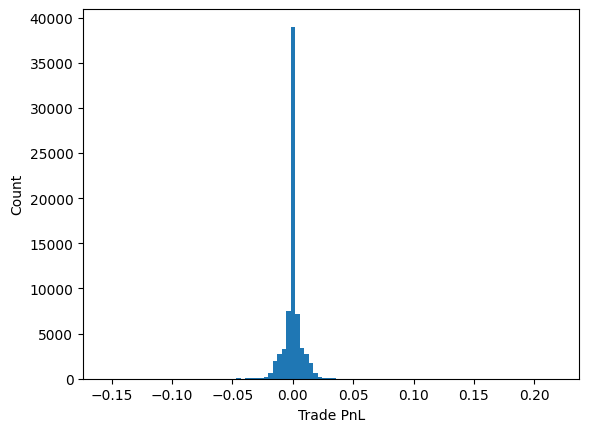

In [12]:
plt.hist(y_dev, bins=100)
plt.xlabel('Trade PnL')
plt.ylabel('Count')
plt.show()

,mean,median,std,count,pos_rate
block,,,,,
0,0.000009,0.000015,0.006712,7200,0.506528
1,0.000138,0.000018,0.008588,7200,0.505139
2,0.000063,0.000013,0.008846,7200,0.502917
3,-0.000151,-0.000023,0.007340,7200,0.493194
4,-0.000107,0.000006,0.006050,7200,0.503611
5,-0.000057,-0.000009,0.007036,7200,0.496528
6,-0.000080,0.000006,0.006897,7200,0.502361
7,0.000003,0.000018,0.006287,7200,0.505972
8,0.000024,0.000002,0.006306,7200,0.500556


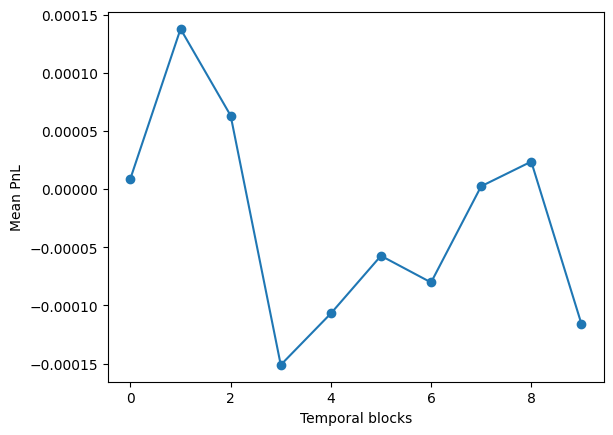

In [13]:
# temporal block consistency check
tmp = dev[[target]].copy()
tmp['block'] = pd.qcut(
    np.arange(len(tmp)),
    q=10,
    labels=False
)

tgb = tmp.groupby('block')[target].agg(
    mean='mean',
    median='median',
    std='std',
    count='size'
)

tgb['pos_rate'] = (
    tmp.assign(positive = tmp[target] > 0).groupby('block')['positive'].mean()
)

display(tgb)
tgb['mean'].plot(marker='o')
plt.xlabel('Temporal blocks')
plt.ylabel('Mean PnL')
plt.show()

In [14]:
# correlation between the 66 features and the target
num_feat = x_dev.columns
pearson = dev[num_feat].corrwith(y_dev)
spearman = dev[num_feat].corrwith(y_dev, method='spearman')
corrs = pd.DataFrame({'perason': pearson, 'spearman': spearman})

corrs['max_abs_corr'] = corrs.abs().max(axis=1)
corrs.sort_values('max_abs_corr', ascending=False).head(15)


,perason,spearman,max_abs_corr
4,-0.067327,0.000391,0.067327
59,0.027160,0.012409,0.027160
61,0.021156,0.009446,0.021156
10,-0.001617,0.019284,0.019284
24,-0.018689,-0.001616,0.018689
22,-0.018382,0.004522,0.018382
60,0.016848,0.007720,0.016848
25,-0.016202,-0.008562,0.016202
12,-0.006544,0.014789,0.014789
52,-0.014229,-0.000337,0.014229


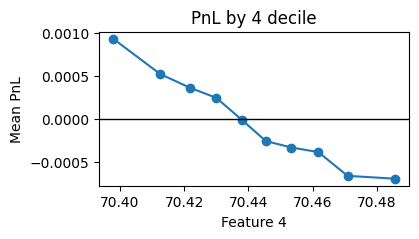

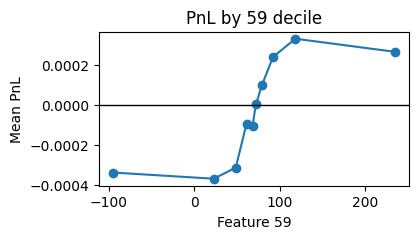

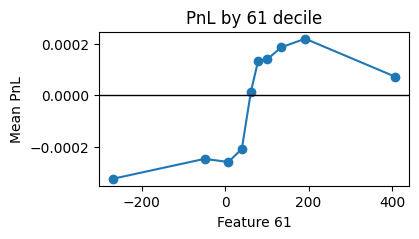

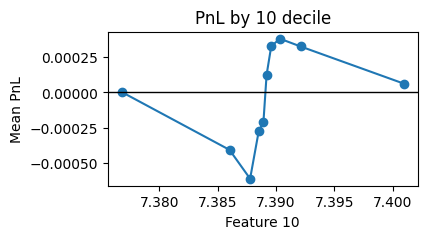

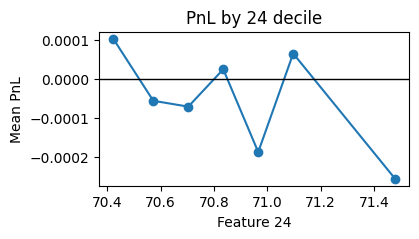

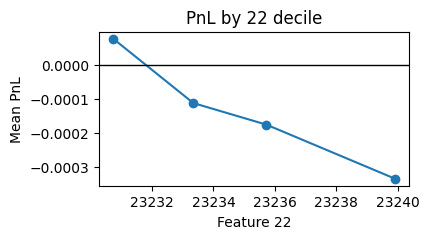

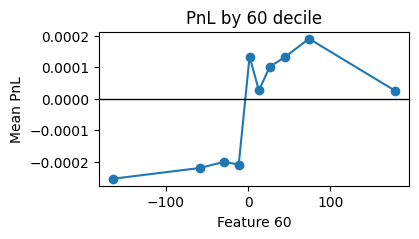

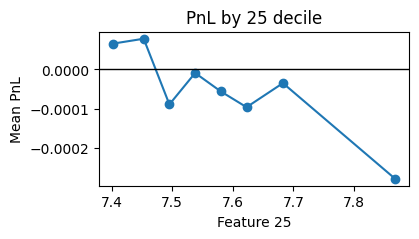

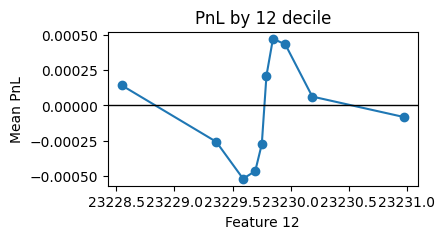

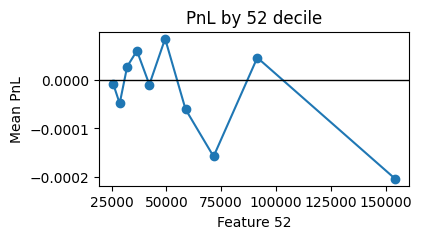

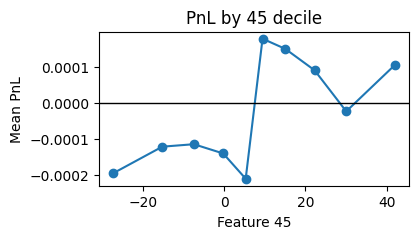

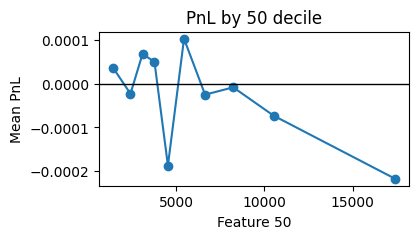

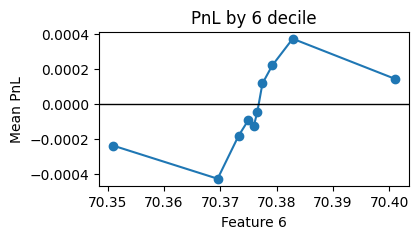

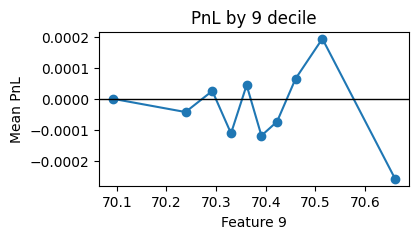

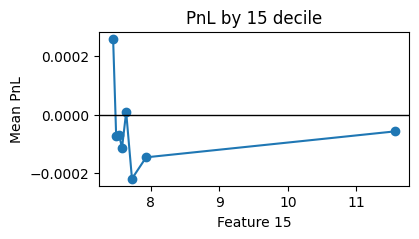

In [50]:
top_feat = (corrs.sort_values('max_abs_corr', ascending=False).head(15).index)


for feat in top_feat:
    probe = dev[[feat, target]].copy()
    probe['bin'] = pd.qcut(probe[feat], q=10, duplicates='drop')
    binned = probe.groupby('bin', observed=True).agg(
        feat_mean=(feat, 'mean'),
        mean_pnl = (target, 'mean'),
        count=(target, 'size')
    )

    plt.figure(figsize=(4,2))
    plt.plot(binned['feat_mean'], binned['mean_pnl'], marker='o')
    plt.axhline(0, color='black', linewidth=1)
    plt.xlabel(f'Feature {feat}')
    plt.ylabel('Mean PnL')
    plt.title(f'PnL by {feat} decile')
    plt.show()

## Model selection

In [19]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.base import clone

# Ridge regression
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
ridge.fit(x_dev, y_dev)
pred_ridge = ridge.predict(x_val)

In [20]:
# Gradient boosting
gbm = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=31,
    l2_regularization=1,
    random_state=42
)

gbm.fit(x_dev, y_dev)
pred_gbm = gbm.predict(x_val)

In [21]:
pred_met = pd.DataFrame({
    'Ridge': {
        'RMSE': np.sqrt(mean_squared_error(y_val, pred_ridge)),
        'MAE': mean_absolute_error(y_val, pred_ridge),
        'pred-target corr': np.corrcoef(pred_ridge, y_val)[0, 1]
    },
    'GB': {
        'RMSE': np.sqrt(mean_squared_error(y_val, pred_gbm)),
        'MAE': mean_absolute_error(y_val, pred_gbm),
        'pred-target corr': np.corrcoef(pred_gbm, y_val)[0, 1]
    }
})

display(pred_met)

,Ridge,GB
RMSE,0.008272,0.008262
MAE,0.005408,0.005366
pred-target corr,0.059327,0.081860


In [22]:
strat_scores = {
    'Feature 4': -x_val['4'].to_numpy(),
    'Ridge': pred_ridge,
    'GB': pred_gbm
}
fractions = np.arange(0.05, 1.01, 0.05)

def eval_strat(score, real_pnl):
    score = np.asarray(score)
    real_pnl = np.asarray(real_pnl)
    rows = []
    for frac in fractions:
        cutoff = np.quantile(score, 1-frac)
        take = score >= cutoff
        rows.append({
            'frac_traded': frac,
            'n_trades': take.sum(),
            'total_pnl': real_pnl[take].sum(),
            'mean_pnl': real_pnl[take].mean(),
            'pos_rate': (real_pnl[take] > 0).mean()
        })

    return pd.DataFrame(rows)

strat_results = {}

for name, score in strat_scores.items():  # score is pred_ridge, pred_gbm etc which is ranked by eval_strat, based on which an optimal fraction is selected

    strat_results[name] = eval_strat(score, y_val)  # using validation subset of train
    print(name)
    display(strat_results[name].sort_values('total_pnl', ascending=False).head(5))

Feature 4


,frac_traded,n_trades,total_pnl,mean_pnl,pos_rate
12,0.65,11700,4.330661,0.000370,0.488889
13,0.70,12600,4.033269,0.000320,0.489206
14,0.75,13500,3.837789,0.000284,0.491630
11,0.60,10800,3.802794,0.000352,0.484907
10,0.55,9900,3.732728,0.000377,0.481515


Ridge


,frac_traded,n_trades,total_pnl,mean_pnl,pos_rate
10,0.55,9900,4.921725,0.000497,0.488687
8,0.45,8100,4.477839,0.000553,0.487407
9,0.50,9000,4.449517,0.000494,0.486667
11,0.60,10800,4.447697,0.000412,0.488889
7,0.40,7200,4.265765,0.000592,0.485139


GB


,frac_traded,n_trades,total_pnl,mean_pnl,pos_rate
10,0.55,9903,6.116795,0.000618,0.493790
9,0.50,9000,6.102075,0.000678,0.492333
8,0.45,8102,6.058418,0.000748,0.491730
11,0.60,10804,6.037644,0.000559,0.493799
7,0.40,7256,5.828360,0.000803,0.492834


In [23]:
trade_all_pnl = y_val.sum()  # trading everything is also a (dummy) strategy

comparison = []

for name, result in strat_results.items():
    best = result.loc[result['total_pnl'].idxmax()]
    comparison.append({
        'strat': name,
        'best_frac': best['frac_traded'],
        'n_trades': best['n_trades'],
        'validation_pnl': best['total_pnl'],
        'mean_pnl_per_trade': best['mean_pnl'],
        'pos_rate': best['pos_rate']
    })

comparison = pd.DataFrame(comparison)
comparison = comparison.sort_values('validation_pnl', ascending=False).reset_index(drop=True)
display(comparison)
print('trade everything:', trade_all_pnl)

,strat,best_frac,n_trades,validation_pnl,mean_pnl_per_trade,pos_rate
0,GB,0.55,9903.0,6.116795,0.000618,0.493790
1,Ridge,0.55,9900.0,4.921725,0.000497,0.488687
2,Feature 4,0.65,11700.0,4.330661,0.000370,0.488889


trade everything: 0.3700202889999997


In [24]:
# Now choosing among the 3 strategies 

best_strat = comparison.loc[0, 'strat']
best_frac = float(comparison.loc[0, 'best_frac'])

# not trading anything is always a (often worst) strategy too
if comparison.loc[0, 'validation_pnl'] <= 0:
    print('no strat produces pos validation pnl --> optimal: trade nothing')
else:
    print('chosen strat:', best_strat)
    print('chosen frac:', best_frac)

chosen strat: GB
chosen frac: 0.55


In [25]:
chosen_score = strat_scores[best_strat]
chosen_cutoff = np.quantile(chosen_score, 1-best_frac)

chosen_mask = chosen_score >= chosen_cutoff

robustness = pd.DataFrame({
    'pnl': y_val.to_numpy(),
    'selected': chosen_mask
})

robustness['block'] = pd.qcut(np.arange(len(robustness)), q=5, labels=False)

block_results = []

for block, x in robustness.groupby('block'):
    sel = x['selected']
    block_results.append({
        'block': block+1,
        'selected_trades': sel.sum(),
        'strat_pnl': x.loc[sel, 'pnl'].sum(),
        'trade_all_pnl': x['pnl'].sum(),
        'mean_selected_pnl': x.loc[sel, 'pnl'].mean() if sel.any() else np.nan
    })

block_results = pd.DataFrame(block_results)
display(block_results)

,block,selected_trades,strat_pnl,trade_all_pnl,mean_selected_pnl
0,1,1781,1.117474,0.159003,0.000627
1,2,2074,1.466068,0.093847,0.000707
2,3,1907,0.876913,-0.288950,0.000460
3,4,2021,1.459669,0.141806,0.000722
4,5,2120,1.196671,0.264314,0.000564


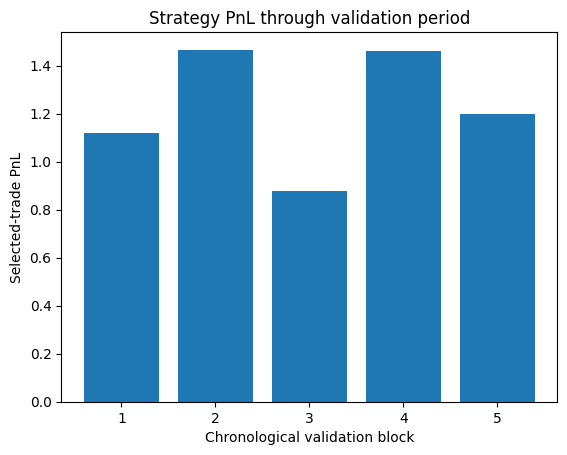

In [26]:
plt.bar(block_results['block'], block_results['strat_pnl'])
plt.xlabel('Chronological validation block')
plt.ylabel('Selected-trade PnL')
plt.title('Strategy PnL through validation period')
plt.show()

In [27]:
# detecting train-to-test features shifts

st_shift = ((test[features].mean() - train[features].mean()).abs() / train[features].std())
shift_table = (
    st_shift.sort_values(ascending=False).to_frame()
)

display(shift_table.head(20))

,0
1,1.073391
2,1.073337
3,1.073323
0,0.695095
20,0.389775
21,0.341017
49,0.288754
47,0.288277
48,0.268923
46,0.240212


In [32]:
shift_table.loc["4"]

0    0.002684
Name: 4, dtype: float64

In [33]:
# Final selection
final_model = clone(gbm)
final_model.fit(train[features], train[target])
test_score = final_model.predict(test[features])  # now using gbm on test, not train

test_cutoff = np.quantile(test_score, 1-best_frac)
test_selected = test_score >= test_cutoff

print('Final model:', best_strat)
print('Fraction selected:', test_selected.mean())
print('Selected test trades:', test_selected.sum())
print('Total test opportunities:', len(test_selected))

Final model: GB
Fraction selected: 0.550007611508601
Selected test trades: 10839
Total test opportunities: 19707


## Conclusion

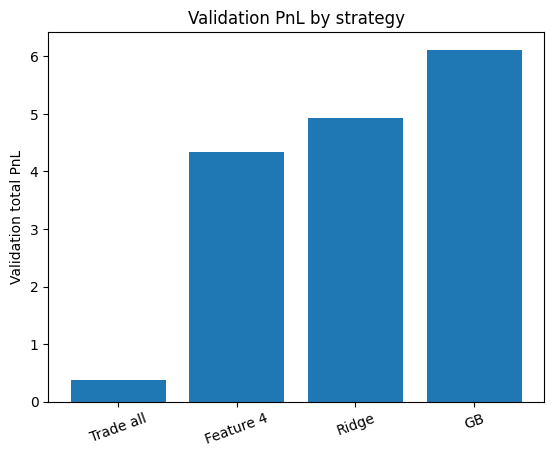

In [34]:
plt.bar(
    ['Trade all', 'Feature 4', 'Ridge', 'GB'],
    [
        trade_all_pnl,
        comparison.loc[comparison['strat'] == 'Feature 4', 'validation_pnl'].iloc[0],
        comparison.loc[comparison['strat'] == 'Ridge', 'validation_pnl'].iloc[0],
        comparison.loc[comparison['strat'] == 'GB', 'validation_pnl'].iloc[0]
    ]
)

plt.ylabel('Validation total PnL')
plt.title('Validation PnL by strategy')
plt.xticks(rotation=20)
plt.show()

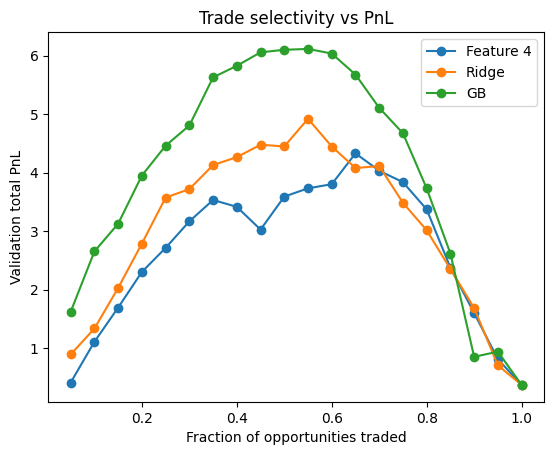

In [35]:
for name, result in strat_results.items():
    plt.plot(
        result['frac_traded'],
        result['total_pnl'],
        marker='o',
        label=name
    )

plt.xlabel('Fraction of opportunities traded')
plt.ylabel('Validation total PnL')
plt.title('Trade selectivity vs PnL')
plt.legend()
plt.show()

### Out-of-sample test <span style='color:red'>(NEW)</span>

In [44]:
y_test = test[target]

# test_score already obtained from the final model trained on all train data
# test_selected already determined using the validation-selected fraction

test_pnl = y_test[test_selected].sum()
test_mean_pnl = y_test[test_selected].mean()
test_pos_rate = (y_test[test_selected] > 0).mean()

trade_all_test_pnl = y_test.sum()

print("Selected test trades:", test_selected.sum())
print("Fraction selected:", test_selected.mean())

print("\nSelected-strategy test PnL:", test_pnl)
print("Mean PnL per selected trade:", test_mean_pnl)
print("Positive-rate selected trades:", test_pos_rate)

print("\nTrade-all test PnL:", trade_all_test_pnl)
print("Trade-nothing test PnL:", 0)
print("Improvement vs trade-all:", test_pnl - trade_all_test_pnl)


test_rmse = np.sqrt(mean_squared_error(y_test, test_score))
test_mae = mean_absolute_error(y_test, test_score)
test_corr = np.corrcoef(test_score, y_test)[0, 1]

print("\n Recall:")
display(pred_met)

Selected test trades: 10839
Fraction selected: 0.550007611508601

Selected-strategy test PnL: 4.3254353521999995
Mean PnL per selected trade: 0.0003990622153519697
Positive-rate selected trades: 0.48943629486114953

Trade-all test PnL: -1.3011567398000004
Trade-nothing test PnL: 0
Improvement vs trade-all: 5.626592092

 Recall:


,Ridge,GB
RMSE,0.008272,0.008262
MAE,0.005408,0.005366
pred-target corr,0.059327,0.081860


In [43]:
final_metrics = pd.DataFrame({
    "Validation": {
        "RMSE": np.sqrt(mean_squared_error(y_val, pred_gbm)),
        "MAE": mean_absolute_error(y_val, pred_gbm),
        "Pred/target corr": np.corrcoef(pred_gbm, y_val)[0, 1],
        "Selected PnL": comparison.loc[
            comparison["strat"] == "GB", "validation_pnl"
        ].iloc[0]
    },
    "Test": {
        "RMSE": test_rmse,
        "MAE": test_mae,
        "Pred/target corr": test_corr,
        "Selected PnL": test_pnl
    }
}).T

display(final_metrics)

,RMSE,MAE,Pred/target corr,Selected PnL
Validation,0.008262,0.005366,0.081860,6.116795
Test,0.009008,0.005782,0.050565,4.325435


In [37]:
# temporal consistency check for the gbm strat in test dataset
test_results = pd.DataFrame({
    "pnl": y_test.to_numpy(),
    "selected": test_selected
})

test_results["block"] = pd.qcut(
    np.arange(len(test_results)),
    5,
    labels=False
)

test_block_rows = []

for block, x in test_results.groupby("block"):
    sel = x["selected"]

    test_block_rows.append({
        "block": block + 1,
        "selected_trades": sel.sum(),
        "strategy_pnl": x.loc[sel, "pnl"].sum(),
        "trade_all_pnl": x["pnl"].sum(),
        "mean_selected_pnl":
            x.loc[sel, "pnl"].mean() if sel.any() else np.nan
    })

test_block_results = pd.DataFrame(test_block_rows)
display(test_block_results)

,block,selected_trades,strategy_pnl,trade_all_pnl,mean_selected_pnl
0,1,2158,1.338143,0.268552,0.000620
1,2,2193,0.190825,-0.664647,0.000087
2,3,2089,1.382238,-0.890742,0.000662
3,4,2173,0.945257,-0.233842,0.000435
4,5,2226,0.468972,0.219522,0.000211


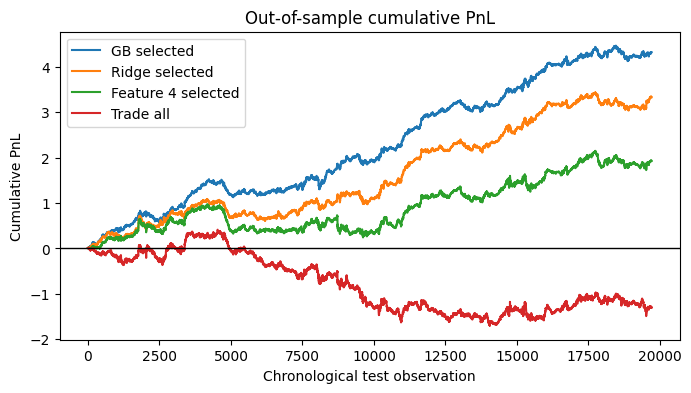

In [46]:
# from looking at the comparison table above...
ridge_strat = comparison.loc[1, 'strat']
ridge_frac = float(comparison.loc[1, 'best_frac'])
final_ridge = clone(ridge)
final_ridge.fit(train[features], train[target])
test_score_ridge = final_ridge.predict(test[features])  
test_cutoff_ridge = np.quantile(test_score_ridge, 1-ridge_frac)
test_selected_ridge = test_score_ridge >= test_cutoff_ridge

feat4_strat = comparison.loc[2, 'strat']
feat4_frac = float(comparison.loc[2, 'best_frac'])
test_score_feat4 = -test[features]['4'].to_numpy()
test_cutoff_feat4 = np.quantile(test_score_feat4, 1-feat4_frac)
test_selected_feat4 = test_score_feat4 >= test_cutoff_feat4



""" final_model = clone(gbm)
final_model.fit(train[features], train[target])
test_score = final_model.predict(test[features])  # now using gbm on test, not train """




test_cumulative = pd.DataFrame({
    "GB selected":
        np.cumsum(y_test.to_numpy() * test_selected),  # remember test_selected is for gbm, the best strat
    "Ridge selected":
        np.cumsum(y_test.to_numpy() * test_selected_ridge),
    "Feature 4 selected":
        np.cumsum(y_test.to_numpy() * test_selected_feat4),
    "Trade all":
        np.cumsum(y_test.to_numpy())
})


test_cumulative.plot(figsize=(8, 4))

plt.xlabel("Chronological test observation")
plt.ylabel("Cumulative PnL")
plt.title("Out-of-sample cumulative PnL")
plt.axhline(0, color="black", linewidth=1)
plt.show()

## Conclusion (complementing the submitted notebook where necessary)

### Findings
- On the 20% validation period (last 20% of the train dataset), GB performed best, achieving a total selected-trade PnL of ~6.12, vs 4.92 for Ridge, 4.33 for Feature-4, and 0.37 from trading every opportunity
- For GB the strongest validation PnL occurred when trading ~the top 55% of opportunities ranked by predicted PnL. The PnL vs selection-fraction curve is relatively flat around the optimum, with 45–60% all producing similar performance
- After freezing the modelling approach and selection fraction, GB  was refitted on all 90,000 labelled observations and used to rank the test opportunities. The final rule selected 10,839 of 19,707 test rows (~55%)

### Limitations
- The original notebook evaluated essentially only the top 5% of trade opportunities for every strategy, so the actual optimization result did not surface due to that indentation error.